# Metropolis escape from deep cubic basins — Figures 1, 2, 3 (v3)

**Every plotted and tabulated value of $H_D(N)$ is computed with exactly the method of `Metropolis_Step3_Reproducible_Figures.ipynb` and the tracked PDF's Section VI-A.** That method is:
- exact sign/permutation-orbit lumping;
- the regenerative identity $H_D(N)=\dfrac{1+p\,g_{ex}(e_1)}{p\,h_{ex}(e_1)}$;
- a float64 sparse LU solve (`splu`, COLAMD), with Step 3's acceptance checks: residual $<10^{-9}$, and two LU orderings agreeing to $10^{-8}$.

The Step 3 functions are copied **byte-for-byte**, and the data loop is Step 3's own loop. There is no fallback solver, no rescaling, and no high-precision value anywhere in the dataset. If Step 3's solver refuses a point, the notebook **stops**; it never substitutes a value.

**Not used to compute any value:** the block-Thomas audits (Step 3's own algorithm) only *compare* against float64 values. Each one is run at **60 and 90 digits**, so it checks both agreement with float64 and stability under increased precision, as the revision plan's Step 3 completion test requires. The cases are Step 3's two, $(2,23,0.2)$ and $(3,8,0.2)$, plus $(2,25,0.15)$, the hardest $D\ge2$ point in this dataset, and $(3,10,0.15)$. Set `RUN_MPMATH_AUDIT = False` to skip them.

**No Monte Carlo simulation.** The original Figure Set 2 used the Markov-chain solution, and the revision plan says "No Monte Carlo program is necessary."

| Figure | Top row | Bottom row | Grid (original figure set) |
|---|---|---|---|
| 1 | $H_D$ (solid), $Q_D$ (dashed) vs $N$ | signed error vs $N$ | $D=1,2,3$; $p=0.2,0.55,0.9$; tracked-PDF $N$ grid |
| 2 | **true walk** $H_D$ | **formula** $Q_D$ | left $N=20$, 50 values $p\in[0.15,0.90]$; right $p=0.55$, $N=5..25$ |
| 3 | $H_D$, $Q_D$ vs $p$ | signed error vs $p$ | $D=1,2,3$; $N=5,15,25$; $p=0.15..0.90$ |

**Why Figure 3 starts at $p=0.15$, not 0.10 as in the original:** Step 3's solver refuses $N=25$, $p=0.10$ in $D=2,3$ (its residual check fails). Without a fallback those two points cannot be computed with this method, so the grid starts at 0.15.

**Run in Google Colab:** *Runtime → Run all* (CPU; about 1–2 minutes). A ZIP downloads at the end.

### 1. Configuration

In [ ]:
import importlib.util, subprocess, sys
if importlib.util.find_spec('mpmath') is None:          # Colab already has it
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mpmath'])

import itertools, json, math, sys, time, zipfile
from datetime import datetime, timezone
from pathlib import Path
import numpy as np, pandas as pd, scipy, matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import splu, spsolve
import mpmath as mp

OUTPUT_DIR = Path('metropolis_figures_123').resolve()

# ---- Figure 1 (original Figure Set 1; tracked PDF Sec. VI-A grid) --------
FIG1_D = (1, 2, 3)
FIG1_P = (0.20, 0.55, 0.90)
FIG1_N = (2, 3, 5, 8, 11, 14, 17, 20, 23, 25)     # exactly the tracked-PDF grid
# FIG1_N = tuple(range(2, 26))                    # denser alternative

# ---- Figure 2 (original Figure Set 2) -----------------------------------
FIG2_D = (1, 2, 3)
FIG2A_N = 20
FIG2A_P = tuple(np.round(np.linspace(0.15, 0.90, 50), 6))   # as in the original caption
FIG2B_P = 0.55
FIG2B_N = tuple(range(5, 26))

# ---- Figure 3 (original Figure Set 3) -----------------------------------
FIG3_D = (1, 2, 3)
FIG3_N = (5, 15, 25)
FIG3_P = (0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55,
          0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90)
# 0.10 is NOT included: Step 3's float64 solver refuses (D=2,3, N=25, p=0.10).
EXTEND_FIG3_TO_P1 = False   # True adds p = 0.95, 0.975, 1.0 (Step 3 solver handles these)

# ---- Table I -------------------------------------------------------------
TABLE_CASES = ((1, 20, 0.30), (2, 20, 0.30), (3, 20, 0.30))

# ---- Step 3 settings (unchanged meaning) ---------------------------------
CHECK_ALTERNATE_LU_ORDERING = True  # Step 3: second LU ordering must agree to 1e-8
RUN_DEEP_MPMATH_CROSSCHECK = True   # Step 3: audit cases (2,23,.2),(3,8,.2)
RUN_MPMATH_AUDIT = True             # False skips the audit entirely (it produces no data)
AUDIT_DPS = (60, 90)                # each audit is repeated at both precisions
AUDIT_CASES = ((2, 23, 0.20),       # Step 3 / tracked-PDF case
               (3, 8, 0.20),        # Step 3 / tracked-PDF case
               (2, 25, 0.15),       # hardest D>=2 point in this dataset (H ~ 2.6e19, Fig. 3)
               (3, 10, 0.15))       # low-p D=3 point (Fig. 3 p, shorter depth)
RUN_HARDEST_D3_AUDIT = False        # (3,25,0.15): hardest D=3 point; dense mpmath, roughly an hour

if EXTEND_FIG3_TO_P1:
    FIG3_P = FIG3_P + (0.95, 0.975, 1.0)
for sub in ('data', 'figures', 'tables'):
    (OUTPUT_DIR / sub).mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.titlesize': 10,
    'axes.labelsize': 9, 'legend.fontsize': 8, 'xtick.labelsize': 8,
    'ytick.labelsize': 8, 'pdf.fonttype': 42, 'ps.fonttype': 42,
    'figure.dpi': 130, 'savefig.bbox': 'tight'})
print('Python', sys.version.split()[0], '| NumPy', np.__version__,
      '| SciPy', scipy.__version__, '| mpmath', mp.__version__)

Python 3.13.18 | NumPy 2.4.6 | SciPy 1.16.3 | mpmath 1.3.0


### 2. Shell-quotient formula $Q_D(N)$ — *unchanged from Step 3*
Eq. (17) of the paper. Exact for the shell-quotient chain; equal to the true walk only for $D=1$.

In [ ]:
def shell_size(m: int, D: int) -> int:
    """Number of lattice points with ||x||_inf = m (m >= 1)."""
    if m < 1 or D < 1:
        raise ValueError('Require m >= 1 and D >= 1')
    return (2*m + 1)**D - (2*m - 1)**D


def quotient_hitting_time(N: int, p: float, D: int) -> float:
    """Exact mean exit time of the shell-SHORTED / shell-AVERAGED chain.

    From Eq. (17) of the paper. For D>1 this is NOT the exact true
    Metropolis hitting time, since the shell projection is not Markov.

    The form below factors alpha^(ell+1), avoiding a double sum of huge
    terms and making the role of F_ell = 1 + sum_m S_D(m) p^m explicit.
    """
    if N < 1 or D < 1 or not (0 < p <= 1):
        raise ValueError('Require N >= 1, D >= 1 and 0 < p <= 1')
    F = 1.0
    total = 0.0
    alpha = 1.0 / p
    power = 1.0
    for ell in range(N):
        if ell > 0:
            F += shell_size(ell, D) * p**ell
        power *= alpha
        total += power * F / (2*ell + 1)**(D-1)
    return total


def quotient_asymptotic_constant(D: int, p: float) -> float:
    """Limit of p**N * N**(D-1) * Q_D(N), fixed D, 0<p<1.

    In D=1,2,3 the sum F_inf is available in closed form.
    This constant belongs to Q_D, NOT automatically to the true chain.
    """
    if not 0 < p < 1 or D not in (1, 2, 3):
        raise ValueError('Supported: D in {1,2,3}, 0 < p < 1')
    if D == 1:
        F_inf = (1 + p) / (1 - p)
    elif D == 2:
        F_inf = 1 + 8*p / (1 - p)**2
    else:
        F_inf = 1 + 24*p*(1+p)/(1-p)**3 + 2*p/(1-p)
    return F_inf / ((1-p) * 2**(D-1))

### 3. True-chain solver — *unchanged from Step 3*
Exact sign/permutation-orbit lumping, plus the regenerative identity $H_D(N)=\dfrac{1+p\,g_{ex}(e_1)}{p\,h_{ex}(e_1)}$. This is the method described in the tracked PDF's Section VI-A.

In [ ]:
def orbit_states(N: int, D: int):
    """All transient sign/permutation orbits, excluding the origin.

    Canonical representative is sorted ABSOLUTE coordinates in ascending
    order, e.g. (0,1,3). This is an EXACT lumping by symmetries.
    The state count (including the origin) is binomial(N+D-1,D).
    """
    return [s for s in itertools.combinations_with_replacement(range(N), D)
            if s[-1] != 0]


def make_excursion_system(N: int, p: float, D: int):
    """Build (I-P_int)*h=b and (I-P_int)*g=1 on non-origin orbits.

    Origin and shell N are absorbing BOUNDARIES for each excursion.
    h(x)=P_x(hit shell N before returning to origin), and
    g(x)=E_x[min(tau_origin,tau_shell_N)].

    When an uphill proposal is rejected, the walk stays at x. This
    self-loop MUST be represented, including on moves toward shell N.
    """
    if not (N >= 2 and D in (1,2,3) and 0 < p <= 1):
        raise ValueError('Require N>=2, D=1,2,3 and 0<p<=1')
    states = orbit_states(N, D)
    loc = {s: i for i, s in enumerate(states)}
    n = len(states)
    rows, cols, weights = [], [], []
    to_outer = np.zeros(n, dtype=float)
    to_origin = np.zeros(n, dtype=float)
    step = 1.0 / (2*D)

    for i, state in enumerate(states):
        radius = state[-1]
        rows.append(i); cols.append(i); weights.append(1.0)
        for coordinate in range(D):
            for direction in (-1, +1):
                neighbor = list(state)
                neighbor[coordinate] += direction
                new_radius = max(abs(z) for z in neighbor)
                uphill = new_radius > radius
                accept = p if uphill else 1.0
                # The rejected move is a REAL self-loop, not absorption.
                if uphill:
                    rows.append(i); cols.append(i)
                    weights.append(-(1.0-p)*step)
                transition = accept * step
                if new_radius == N:
                    to_outer[i] += transition
                elif new_radius == 0:
                    to_origin[i] += transition
                else:
                    canonical = tuple(sorted(abs(z) for z in neighbor))
                    rows.append(i); cols.append(loc[canonical])
                    weights.append(-transition)

    A = coo_matrix((weights, (rows, cols)), shape=(n, n)).tocsc()
    # Independent stochasticity check: A*1 = probability of leaving
    # the excursion state set in one step.
    conservation_error = np.max(np.abs(
        A.dot(np.ones(n)) - (to_origin + to_outer)))
    if conservation_error > 1e-12:
        raise AssertionError(f'Transition conservation failed: {conservation_error}')
    return A, to_outer, to_origin, loc, conservation_error


def componentwise_backward_error(A, x, b) -> float:
    """Relative algebraic residual; useful, not a forward-error proof."""
    residual = np.abs(A.dot(x) - b)
    denominator = abs(A).dot(np.abs(x)) + np.abs(b)
    return float(np.max(residual / np.maximum(denominator, 1e-300)))


def true_hitting_time(N: int, p: float, D: int, check_alt=True) -> dict:
    """Mean true-chain exit time from the origin, in attempted steps.

    This regenerative computation avoids the nearly singular direct
    mean-hitting-time system (I-P)T=1 at huge escape times.
    It uses the exactly lumped ORBIT chain, NOT shell averaging.
    """
    if N == 1:
        return dict(H_true=1/p, orbit_count=0, h_neighbor=1.,
                    g_neighbor=0., error_h=0., error_g=0.,
                    alternative_relative_difference=0.)
    A, b, to_origin, index, conservation_error = make_excursion_system(N,p,D)
    ones = np.ones(A.shape[0])
    lu = splu(A, permc_spec='COLAMD')
    solution = lu.solve(np.column_stack([b, ones]))
    h, g = solution[:, 0], solution[:, 1]
    first_neighbor = (0,)*(D-1) + (1,)
    j = index[first_neighbor]
    if h[j] <= 0 or g[j] < 0 or np.min(h) < -1e-10:
        raise ArithmeticError('Nonphysical excursion solution; inspect conditioning')
    H = (1 + p*g[j])/(p*h[j])
    if not np.isfinite(H) or H <= 0:
        raise ArithmeticError('Invalid true hitting time')
    err_h = componentwise_backward_error(A,h,b)
    err_g = componentwise_backward_error(A,g,ones)
    if max(err_h,err_g) > 1e-9:
        raise ArithmeticError(f'Unacceptable sparse-solve residual: {err_h}, {err_g}')
    alt_diff = np.nan
    if check_alt:
        # M-matrix has positive pivots; avoid unhelpful pivoting and
        # change the permutation ordering for an independent factorization.
        alt = splu(A, permc_spec='MMD_ATA', diag_pivot_thresh=0.0).solve(
            np.column_stack([b,ones]))
        H_alt = (1 + p*alt[j,1])/(p*alt[j,0])
        alt_diff = abs(H_alt/H - 1)
        if alt_diff > 1e-8:
            raise ArithmeticError(f'Independent LU orderings disagree by {alt_diff}')
    return dict(H_true=float(H), orbit_count=A.shape[0],
                h_neighbor=float(h[j]), g_neighbor=float(g[j]),
                error_h=err_h, error_g=err_g,
                alternative_relative_difference=float(alt_diff))

### 4. 60-digit block-Thomas audit — *unchanged from Step 3; audit only*
A different algorithm from Section 3, used only to **compare** against two float64 values. It produces no plotted or tabulated value.

In [ ]:
def high_precision_block_reference(N: int, p: float, D: int, dps: int=60) -> float:
    """Independent HIGH-PRECISION orbit-block Thomas hitting-time solve.

    Adapted from the block-Thomas numerical method in the attached original
    notebook. Unlike the main regenerative solver, this solves (I-P)T=1
    directly using mpmath arithmetic on each shell, so it is useful as an
    independent audit. Intended for a few selected cases, not the full grid.
    D=3, N=25 would be unnecessarily expensive with dense mpmath blocks.
    """
    if D not in (2,3):
        raise ValueError('High-precision block audit supports D=2 or 3')
    with mp.workdps(dps):
        pv = mp.mpf(str(p)); weight = mp.mpf(1)/(2*D)
        shells = [list(itertools.combinations_with_replacement(range(r+1), D-1))
                  for r in range(N)]
        shells = [ [tuple(s)+(r,) for s in group] for r,group in enumerate(shells)]
        # Tuple is ascending; e.g., D=3 shell 3 gives (c,b,3), c<=b<=3.
        where = [{s:i for i,s in enumerate(group)} for group in shells]
        alpha, beta = [None]*N,[None]*N
        for r in range(N):
            nr = len(shells[r]); nxt = len(shells[r+1]) if r+1<N else 0
            prv = len(shells[r-1]) if r>0 else 0
            B=mp.eye(nr)
            U=mp.matrix(nr,nxt) if nxt else None
            L=mp.matrix(nr,prv) if prv else None
            for i,state in enumerate(shells[r]):
                for j in range(D):
                    for di in (-1,1):
                        ns=list(state); ns[j] += di
                        nradius=max(abs(a) for a in ns)
                        pa=pv if nradius>r else mp.mpf(1)
                        if nradius>r:
                            B[i,i] -= weight*(1-pa)
                        if nradius>=N:
                            continue
                        orbit=tuple(sorted(abs(z) for z in ns))
                        t=nradius; coeff=-weight*pa
                        if t==r: B[i,where[r][orbit]] += coeff
                        elif t==r+1: U[i,where[r+1][orbit]] += coeff
                        elif t==r-1: L[i,where[r-1][orbit]] += coeff
                        else: raise RuntimeError('Unexpected radial jump')
            rhs=mp.matrix([1]*nr)
            if r:
                B = B + L*beta[r-1]
                rhs = rhs - L*alpha[r-1]
            alpha[r]=mp.lu_solve(B,rhs)
            if U is not None:
                beta[r]=mp.matrix(nr,nxt)
                for j in range(nxt):
                    solution=mp.lu_solve(B, mp.matrix([-U[i,j] for i in range(nr)]))
                    for i in range(nr): beta[r][i,j]=solution[i]
        vector=alpha[-1]
        for r in range(N-2,-1,-1):
            vector=alpha[r]+beta[r]*vector
        return float(vector[0])


def high_precision_audits():
    cases=[(2, 23, .2, 60), (3, 8, .2, 60)]
    if not RUN_DEEP_MPMATH_CROSSCHECK:
        cases=[(2, 8, .2, 60), (3, 5, .2, 60)]
    rows=[]
    for D,N,p,dps in cases:
        tic=time.perf_counter()
        reference=high_precision_block_reference(N,p,D,dps)
        stable=true_hitting_time(N,p,D)['H_true']
        delta=abs(stable/reference-1)
        rows.append({'D':D,'N':N,'p':p,'mpmath_dps':dps,
                     'H_mpmath_reference':reference,'H_regenerative':stable,
                     'relative_difference':delta, 'runtime_seconds':time.perf_counter()-tic,
                     'passed':bool(delta<1e-10)})
        if delta>1e-10:
            raise AssertionError(f'High-precision block comparison failed: D={D},N={N},p={p}')
        print(f'PASS independent {dps}-digit block reference: D={D}, N={N}, '
              f'p={p}; relative diff={delta:.2e}')
    return rows

### 5. Validation
First come Step 3's 25 tests, unchanged. Then come the **paired-precision audits**: Step 3's `high_precision_block_reference`, unchanged, called at 60 and 90 digits for each case. A case passes only if (i) the 60- and 90-digit results agree to $10^{-15}$ and (ii) the float64 regenerative value agrees with them to $10^{-10}$, the same threshold as Step 3. The 60-digit results for Step 3's two cases reproduce its audit, which the tracked PDF cites.

*Resolution limit:* Step 3's function returns its result rounded to float64, so the 60-vs-90 comparison can resolve changes only down to about $10^{-16}$. It shows that the answer is unchanged to full double precision, not to 60 digits.

Then two new tests, which use only Step 3's float64 solver:
- the exact $N=2$ reversal threshold $p=(\sqrt5-1)/2$ (from $H_2/H_1=(5p^2+12p+1)/(3p^2+10p+3)$);
- the $p=1$ Brownian constant $c_2\approx1.1787$.

In [ ]:
def full_state_direct_hitting_time(N, p, D):
    """Independent SMALL-N full lattice method, used ONLY for tests.

    No symmetry lumping, no excursion decomposition. This naive method
    becomes poorly conditioned in the rare-event regime and must not
    produce paper figure data at large N / low p.
    """
    states = list(itertools.product(range(-N+1, N), repeat=D))
    ids = {x:i for i,x in enumerate(states)}
    rr, cc, vv = [], [], []
    for i,x in enumerate(states):
        rr.append(i); cc.append(i); vv.append(1.)
        rad = max(abs(z) for z in x)
        for j in range(D):
            for direction in (-1,1):
                y = list(x); y[j] += direction
                yr = max(abs(z) for z in y)
                accept = p if yr > rad else 1.
                if accept < 1:
                    rr.append(i); cc.append(i); vv.append(-(1-accept)/(2*D))
                if yr < N:
                    rr.append(i); cc.append(ids[tuple(y)])
                    vv.append(-accept/(2*D))
    M = coo_matrix((vv,(rr,cc)),shape=(len(states),len(states))).tocsc()
    T = spsolve(M, np.ones(len(states)))
    return float(T[ids[(0,)*D]])


def run_tests():
    checks=[]
    def test(name, value, reference, rtol=1e-9):
        relative = abs(value-reference)/max(1.0,abs(reference))
        if not np.isfinite(relative) or relative > rtol:
            raise AssertionError(f'{name}: {value}, expected {reference}, rel={relative}')
        checks.append({'test':name, 'actual':value,
                       'reference':reference, 'relative_difference':relative,
                       'tolerance':rtol, 'passed':True})

    # Special cases derived analytically in the paper/reviews.
    for p in (0.2, 0.55, 0.9):
        for N in (2,5,15,25):
            test(f'D=1 matches Q, N={N},p={p}',
                 true_hitting_time(N,p,1,False)['H_true'],
                 quotient_hitting_time(N,p,1))
    for p in (0.2,0.9):
        test(f'N=2,D=1 exact rational,p={p}',
             true_hitting_time(2,p,1)['H_true'], (1+3*p)/p**2)
        test(f'N=2,D=2 exact rational,p={p}',
             true_hitting_time(2,p,2)['H_true'],
             (5*p*p+12*p+1)/(p*p*(p+3)))
    for D in (1,2,3):
        test(f'quotient p=1 equals N^2, D={D}',
             quotient_hitting_time(7,1,D), 49)

    # Check exact orbit lumping against a truly independent full-state solve.
    for D, N, p in ((1,4,.55),(2,3,.2),(2,4,.9),(3,3,.55)):
        test(f'full-lattice vs orbit D={D},N={N},p={p}',
             true_hitting_time(N,p,D)['H_true'],
             full_state_direct_hitting_time(N,p,D))

    # Hard numerical reference from the critical ChatGPT review (60-digit solve).
    test('Review benchmark D=2,N=23,p=.2',
         true_hitting_time(23,.2,2)['H_true'],
         1.1905397816993633e15,rtol=3e-12)

    # A true-chain dimensional reversal at finite N, not the quotient.
    H1=true_hitting_time(2,.9,1)['H_true']
    H2=true_hitting_time(2,.9,2)['H_true']
    if H2 <= H1:
        raise AssertionError('Expected finite-N counterexample not reproduced')
    checks.append({'test':'finite-N crossover D2 > D1 at N=2,p=.9',
                   'actual':H2, 'reference':H1,
                   'relative_difference':H2/H1-1,
                   'tolerance':None, 'passed':True})
    print(f'PASS: {len(checks)} analytic, full-lattice, and review-reference checks.')
    print(f"Hard benchmark: {true_hitting_time(23,.2,2)['H_true']:.16e}")
    return checks




unit_checks = run_tests()
def paired_precision_audits():
    cases = list(AUDIT_CASES) + ([(3, 25, 0.15)] if RUN_HARDEST_D3_AUDIT else [])
    rows = []
    for D, N, p in cases:
        tic = time.perf_counter()
        ref = {d: high_precision_block_reference(N, p, D, d) for d in AUDIT_DPS}
        lo, hi = ref[min(AUDIT_DPS)], ref[max(AUDIT_DPS)]
        stable = true_hitting_time(N, p, D)['H_true']
        precision_change = abs(lo/hi - 1)
        delta = abs(stable/hi - 1)
        ok = precision_change < 1e-15 and delta < 1e-10
        rows.append({'D': D, 'N': N, 'p': p, 'dps_low': min(AUDIT_DPS), 'dps_high': max(AUDIT_DPS),
                     'H_mpmath_low': lo, 'H_mpmath_high': hi, 'H_regenerative': stable,
                     'precision_change': precision_change, 'relative_difference': delta,
                     'runtime_seconds': time.perf_counter() - tic, 'passed': ok})
        if not ok:
            raise AssertionError(f'Paired audit failed D={D},N={N},p={p}: '
                                 f'precision change {precision_change:.1e}, float64 diff {delta:.1e}')
        print(f'PASS {min(AUDIT_DPS)}/{max(AUDIT_DPS)}-digit audit D={D} N={N:2d} p={p}: '
              f'precision change {precision_change:.1e}, float64 vs mpmath {delta:.1e} '
              f'({rows[-1]["runtime_seconds"]:.0f}s)')
    return rows

mp_checks = paired_precision_audits() if RUN_MPMATH_AUDIT else []

def new_tests():
    out = []
    def rec(name, ok, detail):
        if not ok: raise AssertionError(f'{name}: {detail}')
        out.append(dict(test=name, passed=True, detail=detail))
    H = lambda N, p, D: true_hitting_time(N, p, D)['H_true']
    g = (5**0.5 - 1)/2
    lo, hi = H(2, g-1e-3, 2)/H(2, g-1e-3, 1), H(2, g+1e-3, 2)/H(2, g+1e-3, 1)
    rec('N=2 reversal at p=(sqrt5-1)/2', lo < 1 < hi, f'{lo:.6f} -> {hi:.6f}')
    c2 = H(100, 1.0, 2)/100**2
    rec('p=1 Brownian constant c_2', abs(c2 - 1.1787) < 2e-3, f'H/N^2={c2:.5f}')
    print(f'PASS: {len(out)} additional tests (Step 3 solver only).')
    return out

extra_checks = new_tests()

PASS: 25 analytic, full-lattice, and review-reference checks.
Hard benchmark: 1.1905397816993685e+15
PASS 60/90-digit audit D=2 N=23 p=0.2: precision change 0.0e+00, float64 vs mpmath 4.4e-15 (25s)
PASS 60/90-digit audit D=3 N= 8 p=0.2: precision change 0.0e+00, float64 vs mpmath 5.6e-15 (10s)
PASS 60/90-digit audit D=2 N=25 p=0.15: precision change 0.0e+00, float64 vs mpmath 3.0e-15 (17s)
PASS 60/90-digit audit D=3 N=10 p=0.15: precision change 0.0e+00, float64 vs mpmath 1.4e-14 (60s)
PASS: 2 additional tests (Step 3 solver only).


### 6. Compute the single dataset `all_results.csv` — *Step 3's data loop*
This is Step 3's loop, unchanged, except that the requested set is the union of all figure grids and a `used_in` column is added. Each value comes from `true_hitting_time(N, p, D, check_alt=CHECK_ALTERNATE_LU_ORDERING)`. A refused point stops the notebook.

In [ ]:
used = {}
def want(D, N, p, tag): used.setdefault((D, N, round(float(p), 10)), set()).add(tag)
for D in FIG1_D:
    for p in FIG1_P:
        for N in FIG1_N: want(D, N, p, 'fig1')
for D in FIG2_D:
    for p in FIG2A_P: want(D, FIG2A_N, p, 'fig2a')
    for N in FIG2B_N: want(D, N, FIG2B_P, 'fig2b')
for D in FIG3_D:
    for N in FIG3_N:
        for p in FIG3_P: want(D, N, p, 'fig3')
for D, N, p in TABLE_CASES: want(D, N, p, 'table')
requested = set(used)

records=[]
start = time.perf_counter()
for D,N,p in sorted(requested):
    audit=true_hitting_time(N,p,D,check_alt=CHECK_ALTERNATE_LU_ORDERING)
    Q=quotient_hitting_time(N,p,D)
    H=audit['H_true']
    records.append({
        'D':D,'N':N,'p':p,
        'Q_quotient':Q,'H_true':H,
        'signed_error_pct':100*(Q/H-1),
        'H_over_Q':H/Q,
        'normalized_Q':Q*(p**N)*N**(D-1),
        'normalized_H':H*(p**N)*N**(D-1),
        **audit,
        'method': 'exact symmetry-orbit + regenerative sparse LU',
        'precision': 'float64',
        'used_in': ';'.join(sorted(used[(D,N,p)])),
    })
results=pd.DataFrame.from_records(records).sort_values(['D','p','N']).reset_index(drop=True)
elapsed=time.perf_counter()-start
assert len(results)==len(requested)
assert results[['D','N','p']].duplicated().sum()==0
assert np.isfinite(results[['Q_quotient','H_true']]).to_numpy().all()
assert (results['H_true']>0).all()
assert (results['Q_quotient']>0).all()
assert results.method.nunique()==1 and results.precision.eq('float64').all()
if (results['signed_error_pct']>1e-8).any():
    print('NOTE: Q > H on some tested points; no global Q <= H theorem is assumed.')
print(f'Computed {len(results)} validated parameter combinations in {elapsed:.2f} seconds.')
print('Every value: exact symmetry-orbit + regenerative sparse LU, float64.')
print('Largest relative difference between independent sparse LU orderings:',
      f"{results['alternative_relative_difference'].max():.3e}")
print('Largest componentwise backward error:', f"{results[['error_h','error_g']].max().max():.3e}")
results.to_csv(OUTPUT_DIR/'data'/'all_results.csv', index=False, float_format='%.16g')
pd.DataFrame(unit_checks + extra_checks).to_csv(OUTPUT_DIR/'data'/'unit_checks.csv', index=False)
pd.DataFrame(mp_checks).to_csv(OUTPUT_DIR/'data'/'high_precision_crosschecks.csv', index=False)

Computed 402 validated parameter combinations in 6.18 seconds.
Every value: exact symmetry-orbit + regenerative sparse LU, float64.
Largest relative difference between independent sparse LU orderings: 1.010e-13
Largest componentwise backward error: 3.732e-14


### 7. Check every number quoted in the tracked PDF's Section VI
Each value is recomputed from `all_results.csv` and compared at the precision the PDF prints. A mismatch is reported (not hidden), so the text can be fixed.

In [ ]:
R = pd.read_csv(OUTPUT_DIR/'data'/'all_results.csv')
def row(D, N, p): return R[(R.D == D) & (R.N == N) & np.isclose(R.p, p)].iloc[0]
def H2(N, p, D): return true_hitting_time(N, p, D)['H_true']
tracked = R[R.used_in.str.contains('fig1|table')]
claims = [
    ('Sec VI-B: delta at N=25, D=2, p=0.2 (%)', -1.37, row(2, 25, .2).signed_error_pct, 2),
    ('Sec VI-B: delta at N=25, D=3, p=0.2 (%)', -2.82, row(3, 25, .2).signed_error_pct, 2),
    ('Sec VI-B: delta at N=25, D=2, p=0.9 (%)', -14.49, row(2, 25, .9).signed_error_pct, 2),
    ('Sec VI-B: delta at N=25, D=3, p=0.9 (%)', -25.52, row(3, 25, .9).signed_error_pct, 2),
    ('Table I: Q_1(20)', 7.6089e10, row(1, 20, .3).Q_quotient, None),
    ('Table I: Q_2(20)', 6.3472e9, row(2, 20, .3).Q_quotient, None),
    ('Table I: Q_3(20)', 8.2563e8, row(3, 20, .3).Q_quotient, None),
    ('Table I: H_1(20)', 7.6089e10, row(1, 20, .3).H_true, None),
    ('Table I: H_2(20)', 6.5264e9, row(2, 20, .3).H_true, None),
    ('Table I: H_3(20)', 8.7548e8, row(3, 20, .3).H_true, None),
    ('Table I: delta_2 (%)', -2.75, row(2, 20, .3).signed_error_pct, 2),
    ('Table I: delta_3 (%)', -5.69, row(3, 20, .3).signed_error_pct, 2),
    ('Sec VI-B: H_1/H_2 at N=20,p=0.3', 11.66, row(1, 20, .3).H_true/row(2, 20, .3).H_true, 2),
    ('Sec VI-B: H_1/H_3 at N=20,p=0.3', 86.91, row(1, 20, .3).H_true/row(3, 20, .3).H_true, 2),
    ('Sec VI-B: H_1(2) at p=0.9', 4.5679, H2(2, .9, 1), 4),
    ('Sec VI-B: H_2(2) at p=0.9', 5.0174, H2(2, .9, 2), 4),
    ('Sec VI-A: number of cases', 93, None, None),
    ('Sec VI-A: max backward error (<)', 8e-16, tracked[['error_h', 'error_g']].max().max(), 'lt'),
    ('Sec VI-A: max LU-ordering diff (<)', 4.1e-15, tracked.alternative_relative_difference.max(), 'lt'),
]
step3_cases = [r for r in mp_checks if (r['D'], r['N'], r['p']) in ((2, 23, 0.2), (3, 8, 0.2))]
if step3_cases:
    claims.append(('Sec VI-A: 60-digit audits agree within (<)', 6e-15,
                   max(abs(r['H_regenerative']/r['H_mpmath_low'] - 1) for r in step3_cases), 'lt'))
out = []
for name, quoted, val, dec in claims:
    if val is None:
        n93 = len(R[R.used_in.str.contains('fig1|table')]) if FIG1_N == (2,3,5,8,11,14,17,20,23,25) else None
        ok = n93 == 93; val = n93
    elif dec == 'lt':  ok = val < quoted
    elif dec is None:  ok = float(f'{val:.4e}') == quoted
    else:              ok = round(val, dec) == quoted
    out.append(dict(claim=name, tracked_pdf=quoted, recomputed=val, match=bool(ok)))
claims_df = pd.DataFrame(out)
claims_df.to_csv(OUTPUT_DIR/'data'/'tracked_pdf_number_check.csv', index=False)
with pd.option_context('display.width', 140, 'display.max_colwidth', 50):
    print(claims_df.to_string(index=False))
print('\nALL MATCH' if claims_df.match.all() else
      '\nMISMATCHES above: update the tracked PDF text (machine-dependent residual bounds may differ slightly).')

                                     claim   tracked_pdf    recomputed  match
   Sec VI-B: delta at N=25, D=2, p=0.2 (%) -1.370000e+00 -1.372701e+00   True
   Sec VI-B: delta at N=25, D=3, p=0.2 (%) -2.820000e+00 -2.821789e+00   True
   Sec VI-B: delta at N=25, D=2, p=0.9 (%) -1.449000e+01 -1.448515e+01   True
   Sec VI-B: delta at N=25, D=3, p=0.9 (%) -2.552000e+01 -2.551946e+01   True
                          Table I: Q_1(20)  7.608900e+10  7.608905e+10   True
                          Table I: Q_2(20)  6.347200e+09  6.347225e+09   True
                          Table I: Q_3(20)  8.256300e+08  8.256329e+08   True
                          Table I: H_1(20)  7.608900e+10  7.608905e+10   True
                          Table I: H_2(20)  6.526400e+09  6.526391e+09   True
                          Table I: H_3(20)  8.754800e+08  8.754794e+08   True
                      Table I: delta_2 (%) -2.750000e+00 -2.745261e+00   True
                      Table I: delta_3 (%) -5.690000e+00 -5.6936

### 8. Figures
Each is saved as vector PDF (for LaTeX), editable SVG and PNG, and is drawn **only** from `all_results.csv`.

In [ ]:
R = pd.read_csv(OUTPUT_DIR/'data'/'all_results.csv')
def sel(tag, **kw):
    d = R[R.used_in.str.contains(tag)]
    for k, v in kw.items(): d = d[np.isclose(d[k], v)]
    return d
def save(fig, stem):
    for ext in ('pdf', 'svg', 'png'):
        fig.savefig(OUTPUT_DIR/'figures'/f'{stem}.{ext}', dpi=250, facecolor='white')
    plt.show(); plt.close(fig); print('Saved', stem)

P_COL = {0.20: '#17679a', 0.55: '#c56b20', 0.90: '#16816d'}
D_COL = {1: '#2b5aa8', 2: '#8c2d2d', 3: '#2e7d32'}; D_MK = {1: 'o', 2: 's', 3: '^'}
N_COL = {5: '#9ecae1', 15: '#4292c6', 25: '#08306b'}; N_MK = {5: 'o', 15: 's', 25: '^'}
ERR_YLIM = (min(-5, 1.08*R[R.D > 1].signed_error_pct.min()), 2)   # shared by Figs 1 and 3

#### Figure 1 — escape time and error vs basin depth (original Figure Set 1)

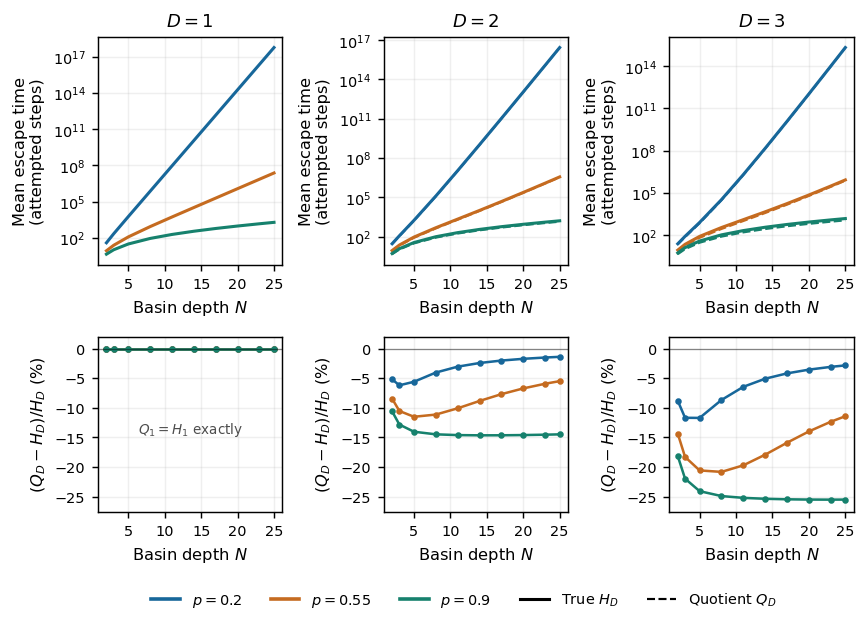

Saved fig1_escape_and_error_vs_depth


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(7.5, 5.0), sharex=True,
                       gridspec_kw=dict(height_ratios=[1.3, 1], hspace=0.36, wspace=0.55))
for c, D in enumerate(FIG1_D):
    for p in FIG1_P:
        a = sel('fig1', D=D, p=p).sort_values('N')
        ax[0, c].semilogy(a.N, a.H_true, '-', color=P_COL[p], lw=1.7)
        if D > 1: ax[0, c].semilogy(a.N, a.Q_quotient, '--', color=P_COL[p], lw=1.2)
        ax[1, c].plot(a.N, a.signed_error_pct, 'o-', color=P_COL[p], ms=2.6, lw=1.4)
    ax[0, c].set_title(f'$D={D}$'); ax[1, c].axhline(0, color='k', lw=.7, alpha=.45)
    ax[1, c].set_xlabel('Basin depth $N$'); ax[1, c].set_ylim(*ERR_YLIM)
    for r in (0, 1): ax[r, c].grid(True, alpha=.2)
ax[0, 0].set_ylabel('Mean escape time\n(attempted steps)')
ax[1, 0].set_ylabel(r'$(Q_D-H_D)/H_D$ (%)')
ax[1, 0].text(.5, .45, '$Q_1=H_1$ exactly', transform=ax[1, 0].transAxes, ha='center', fontsize=7.5, color='.3')
for x in ax.flat:
    x.set_xticks(range(5, max(FIG1_N) + 1, 5))
    x.tick_params(labelbottom=True, labelleft=True)
    x.set_xlabel('Basin depth $N$')
for x in ax[0]: x.set_ylabel('Mean escape time\n(attempted steps)')
for x in ax[1]: x.set_ylabel(r'$(Q_D-H_D)/H_D$ (%)')
h = [Line2D([0], [0], color=P_COL[p], lw=2, label=f'$p={p:g}$') for p in FIG1_P]
h += [Line2D([0], [0], color='k', lw=1.7, label='True $H_D$'),
      Line2D([0], [0], color='k', lw=1.2, ls='--', label='Quotient $Q_D$')]
fig.legend(handles=h, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(.5, -.02))
fig.subplots_adjust(bottom=.15)
save(fig, 'fig1_escape_and_error_vs_depth')

#### Figure 2 — dimensional speedup: true walk (top) and formula (bottom) (original Figure Set 2)

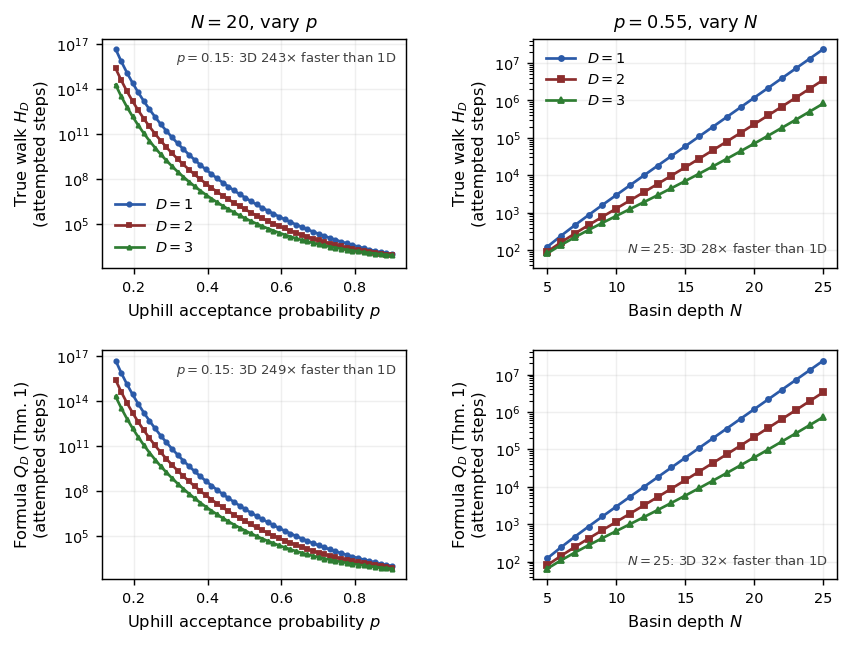

Saved fig2_dimensional_speedup


In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(7.3, 5.4), sharex='col', sharey='col',
                       gridspec_kw=dict(hspace=.36, wspace=.42))
for D in FIG2_D:
    a = sel('fig2a', D=D).sort_values('p'); b = sel('fig2b', D=D).sort_values('N')
    for r, col in ((0, 'H_true'), (1, 'Q_quotient')):
        ax[r, 0].semilogy(a.p, a[col], '-', marker=D_MK[D], ms=2.4, lw=1.5, color=D_COL[D], label=f'$D={D}$')
        ax[r, 1].semilogy(b.N, b[col], '-', marker=D_MK[D], ms=2.8, lw=1.5, color=D_COL[D], label=f'$D={D}$')

def ratio(tag, col, key, val):
    d = sel(tag); d = d[np.isclose(d[key], val)].set_index('D')[col]; return d[1]/d[3]
pa, nb = min(FIG2A_P), max(FIG2B_N)
for r, col, lab in ((0, 'H_true', 'true walk'), (1, 'Q_quotient', 'formula')):
    ax[r, 0].text(.97, .95, f'$p={pa:g}$: 3D {ratio("fig2a", col, "p", pa):.0f}× faster than 1D',
                  transform=ax[r, 0].transAxes, ha='right', va='top', fontsize=7.3, color='.25')
    ax[r, 1].text(.97, .05, f'$N={nb}$: 3D {ratio("fig2b", col, "N", nb):.0f}× faster than 1D',
                  transform=ax[r, 1].transAxes, ha='right', va='bottom', fontsize=7.3, color='.25')
ax[0, 0].set_title(f'$N={FIG2A_N}$, vary $p$'); ax[0, 1].set_title(f'$p={FIG2B_P:g}$, vary $N$')
ax[0, 0].set_ylabel('True walk $H_D$\n(attempted steps)')
ax[1, 0].set_ylabel('Formula $Q_D$ (Thm. 1)\n(attempted steps)')
ax[1, 0].set_xlabel('Uphill acceptance probability $p$'); ax[1, 1].set_xlabel('Basin depth $N$')
for x in ax.flat:
    x.grid(True, alpha=.2); x.tick_params(labelbottom=True, labelleft=True)
for x in ax[:, 1]: x.set_xticks(range(5, max(FIG2B_N) + 1, 5))
for r in (0, 1):
    ax[r, 0].set_xlabel('Uphill acceptance probability $p$'); ax[r, 1].set_xlabel('Basin depth $N$')
ax[0, 1].set_ylabel('True walk $H_D$\n(attempted steps)')
ax[1, 1].set_ylabel('Formula $Q_D$ (Thm. 1)\n(attempted steps)')
ax[0, 0].legend(frameon=False, loc='lower left'); ax[0, 1].legend(frameon=False, loc='upper left')
save(fig, 'fig2_dimensional_speedup')

#### Figure 3 — escape time and error vs acceptance probability (original Figure Set 3)

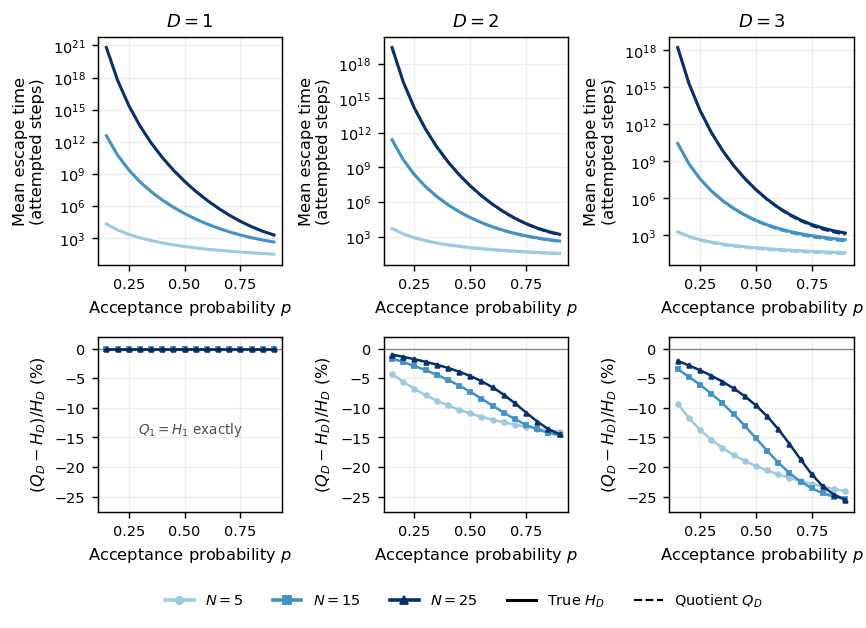

Saved fig3_escape_and_error_vs_p


In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(7.5, 5.0), sharex=True,
                       gridspec_kw=dict(height_ratios=[1.3, 1], hspace=.36, wspace=.55))
for c, D in enumerate(FIG3_D):
    for N in FIG3_N:
        a = sel('fig3', D=D, N=N).sort_values('p')
        ax[0, c].semilogy(a.p, a.H_true, '-', color=N_COL[N], lw=1.7)
        if D > 1: ax[0, c].semilogy(a.p, a.Q_quotient, '--', color=N_COL[N], lw=1.2)
        ax[1, c].plot(a.p, a.signed_error_pct, '-', marker=N_MK[N], color=N_COL[N], ms=2.6, lw=1.4)
    ax[0, c].set_title(f'$D={D}$'); ax[1, c].axhline(0, color='k', lw=.7, alpha=.45)
    ax[1, c].set_ylim(*ERR_YLIM)
    for r in (0, 1): ax[r, c].grid(True, alpha=.2)
ax[0, 0].set_ylabel('Mean escape time\n(attempted steps)')
ax[1, 0].set_ylabel(r'$(Q_D-H_D)/H_D$ (%)')
ax[1, 0].text(.5, .45, '$Q_1=H_1$ exactly', transform=ax[1, 0].transAxes, ha='center', fontsize=7.5, color='.3')
for x in ax.flat:
    x.tick_params(labelbottom=True, labelleft=True); x.set_xlabel('Acceptance probability $p$')
for x in ax[0]: x.set_ylabel('Mean escape time\n(attempted steps)')
for x in ax[1]: x.set_ylabel(r'$(Q_D-H_D)/H_D$ (%)')
h = [Line2D([0], [0], color=N_COL[N], lw=2, marker=N_MK[N], ms=4, label=f'$N={N}$') for N in FIG3_N]
h += [Line2D([0], [0], color='k', lw=1.7, label='True $H_D$'),
      Line2D([0], [0], color='k', lw=1.2, ls='--', label='Quotient $Q_D$')]
fig.legend(handles=h, loc='lower center', ncol=5, frameon=False, bbox_to_anchor=(.5, -.02))
fig.subplots_adjust(bottom=.15)
save(fig, 'fig3_escape_and_error_vs_p')

### 9. Table I, captions and summary — generated and **checked** from the data
Each sentence that makes a claim is written only if the corresponding check passes. Otherwise a weaker sentence is used and a warning is printed.

In [ ]:
def tex_sci(x, sig=5):
    e = int(math.floor(math.log10(abs(x)))); return rf'${x/10**e:.{sig-1}f}\times10^{{{e}}}$'
t = R[R.used_in.str.contains('table')].sort_values('D')
L = [r'\begin{table}[t]', r'\centering',
     r'\caption{Mean escape times at $N=20$, $p=0.3$, in attempted steps. '
     r'$\delta=100(Q_D/H_D-1)$ is the signed percentage discrepancy.}',
     r'\label{tab:escape-example}', r'\begin{tabular}{rrrr}', r'\toprule',
     r'$D$ & $Q_D(20)$ & $H_D(20)$ & $\delta$ (\%) \\', r'\midrule']
for _, r in t.iterrows():
    e = 0.0 if abs(r.signed_error_pct) < 1e-8 else r.signed_error_pct
    L.append(f'{int(r.D)} & {tex_sci(r.Q_quotient)} & {tex_sci(r.H_true)} & {e:.2f} \\\\')
L += [r'\bottomrule', r'\end{tabular}', r'\end{table}']
(OUTPUT_DIR/'tables'/'table_I_N20_p03.tex').write_text('\n'.join(L) + '\n')

def ordered(tag, col):
    """True if 3D < 2D < 1D at every plotted point of this panel."""
    d = sel(tag); key = 'p' if tag == 'fig2a' else 'N'
    w = d.pivot_table(index=key, columns='D', values=col)
    return bool(((w[3] < w[2]) & (w[2] < w[1])).all())
true_ord = ordered('fig2a', 'H_true') and ordered('fig2b', 'H_true')
form_ord = ordered('fig2a', 'Q_quotient') and ordered('fig2b', 'Q_quotient')
f3 = sel('fig3'); f3w = f3[f3.D > 1]
# 'grows': |error| strictly increases between EVERY pair of consecutive p, for every (D,N), D>=2
grows = all(np.all(np.diff(f3w[(f3w.D == D) & (f3w.N == N)].sort_values('p').signed_error_pct.abs()) > 0)
            for D in (2, 3) for N in FIG3_N)
# 'dec_p_max': largest p such that, at every tested p <= it, |error| strictly decreases across N, both D
def dec_in_N(p):
    return all(np.all(np.diff(f3w[(f3w.D == D) & np.isclose(f3w.p, p)].sort_values('N').signed_error_pct.abs()) < 0)
               for D in (2, 3))
dec_p_max = None
for p in sorted(FIG3_P):
    if dec_in_N(p): dec_p_max = p
    else: break
if not true_ord: print('WARNING: true-walk ordering 3D<2D<1D fails somewhere in Fig 2; caption weakened.')

def e(tag, D, N, p): return sel(tag, D=D, N=N, p=p).signed_error_pct.item()
Nm, pm = max(FIG1_N), max(FIG3_P)
cap = {}
cap[1] = (rf"True Metropolis mean escape time $H_D(N)$ (solid) and shell-quotient mean $Q_D(N)$ (dashed) "
          rf"versus basin depth (top), and signed discrepancy $100(Q_D/H_D-1)$ (bottom), for $D=1,2,3$ and "
          rf"$p={', '.join(f'{p:g}' for p in FIG1_P)}$. At $D=1$ the two coincide exactly. Times count "
          rf"attempted moves, including rejected proposals. At $N={Nm}$ the discrepancy is "
          rf"{e('fig1',2,Nm,.2):.2f}\% ($D=2$) and {e('fig1',3,Nm,.2):.2f}\% ($D=3$) at $p=0.2$, and "
          rf"{e('fig1',2,Nm,.9):.2f}\% and {e('fig1',3,Nm,.9):.2f}\% at $p=0.9$.")
cap[2] = (rf"Dimensional dependence of the mean escape time. Top: true Metropolis walk $H_D$. Bottom: "
          rf"shell-quotient formula $Q_D$ (Theorem 1). Left: $N={FIG2A_N}$, $p\in[{min(FIG2A_P):g},{max(FIG2A_P):g}]$ "
          rf"({len(FIG2A_P)} values). Right: $p={FIG2B_P:g}$, $N={min(FIG2B_N)},\dots,{max(FIG2B_N)}$. "
          + (rf"At every plotted point the true walk satisfies $H_3<H_2<H_1$; " if true_ord else
             rf"The true-walk ordering is not uniform over the plotted points; ")
          + rf"at $p={pa:g}$, $N={FIG2A_N}$ the three-dimensional walk escapes "
          rf"{ratio('fig2a','H_true','p',pa):.0f} times faster than the one-dimensional walk "
          rf"(formula: {ratio('fig2a','Q_quotient','p',pa):.0f}). Theorem 4 gives "
          rf"$H_D(N)/H_1(N)=\Theta(N^{{-(D-1)}})$ for fixed $p<1$; in shallow basins at weak bias the "
          rf"true-walk ordering can reverse (Section VI-B)"
          + (rf", whereas the quotient values satisfy $Q_3<Q_2<Q_1$ at every plotted point." if form_ord else "."))
cap[3] = (rf"Mean escape time (top) and signed discrepancy $100(Q_D/H_D-1)$ (bottom) versus uphill acceptance "
          rf"probability $p$ for $N={', '.join(map(str, FIG3_N))}$ and $D=1,2,3$. "
          + (rf"For $D=2,3$ and each tested depth, the discrepancy magnitude increases monotonically "
             rf"over the tested values of $p$. " if grows else "")
          + ((rf"At $p={dec_p_max:g}$, " if dec_p_max == min(FIG3_P) else
              rf"At each tested $p\le{dec_p_max:g}$, ")
             + rf"the discrepancy magnitude decreases across the tested depths $N={', '.join(map(str, FIG3_N))}$. "
             if dec_p_max is not None else "")
          + rf"At $p={pm:g}$ and $N={max(FIG3_N)}$ it is {e('fig3',2,max(FIG3_N),pm):.1f}\% ($D=2$) and "
          rf"{e('fig3',3,max(FIG3_N),pm):.1f}\% ($D=3$).")
txt = '\n\n'.join(f'Fig. {k}. {v}' for k, v in cap.items())
(OUTPUT_DIR/'captions.md').write_text(txt + '\n')
print(txt)
print(f'\nChecks: true ordering {true_ord}, formula ordering {form_ord}, '
      f'|error| increases with p at every step {grows}, '
      f'|error| decreases with N for all p <= {dec_p_max}')

Fig. 1. True Metropolis mean escape time $H_D(N)$ (solid) and shell-quotient mean $Q_D(N)$ (dashed) versus basin depth (top), and signed discrepancy $100(Q_D/H_D-1)$ (bottom), for $D=1,2,3$ and $p=0.2, 0.55, 0.9$. At $D=1$ the two coincide exactly. Times count attempted moves, including rejected proposals. At $N=25$ the discrepancy is -1.37\% ($D=2$) and -2.82\% ($D=3$) at $p=0.2$, and -14.49\% and -25.52\% at $p=0.9$.

Fig. 2. Dimensional dependence of the mean escape time. Top: true Metropolis walk $H_D$. Bottom: shell-quotient formula $Q_D$ (Theorem 1). Left: $N=20$, $p\in[0.15,0.9]$ (50 values). Right: $p=0.55$, $N=5,\dots,25$. At every plotted point the true walk satisfies $H_3<H_2<H_1$; at $p=0.15$, $N=20$ the three-dimensional walk escapes 243 times faster than the one-dimensional walk (formula: 249). Theorem 4 gives $H_D(N)/H_1(N)=\Theta(N^{-(D-1)})$ for fixed $p<1$; in shallow basins at weak bias the true-walk ordering can reverse (Section VI-B), whereas the quotient values sa

### 10. Manifest and download

In [ ]:
manifest = dict(
    created_utc=datetime.now(timezone.utc).isoformat(),
    based_on='Metropolis_Step3_Reproducible_Figures.ipynb (solver, tests, data loop, audits unchanged)',
    value_method='exact symmetry-orbit + regenerative sparse LU, float64, for every value',
    dataset='data/all_results.csv (single source for all figures and Table I)',
    model='V(x)=||x||_inf on Z^D, nearest-neighbour proposals, uphill accept p, absorb on shell N',
    time_units='attempted moves including rejected proposals',
    unique_points=len(R),
    tests_passed=len(unit_checks) + len(extra_checks),
    paired_precision_audits_compare_only=[(r['D'], r['N'], r['p'], r['dps_low'], r['dps_high']) for r in mp_checks],
    tracked_pdf_numbers_all_match=bool(claims_df.match.all()),
    config=dict(FIG1_N=FIG1_N, FIG1_P=FIG1_P, FIG2A_N=FIG2A_N, FIG2A_P_range=[min(FIG2A_P), max(FIG2A_P), len(FIG2A_P)],
                FIG2B_P=FIG2B_P, FIG2B_N=FIG2B_N, FIG3_N=FIG3_N, FIG3_P=FIG3_P),
    versions=dict(python=sys.version.split()[0], numpy=np.__version__, scipy=scipy.__version__,
                  pandas=pd.__version__, matplotlib=matplotlib.__version__, mpmath=mp.__version__),
    caveats=['Q_D <= H_D is observed in all computed cases, not proved.',
             'Residual and LU-ordering checks are not forward-error certificates; '
             'mpmath audits are comparisons only, repeated at 60 and 90 digits.'])
(OUTPUT_DIR/'manifest.json').write_text(json.dumps(manifest, indent=2, default=str) + '\n')
zp = OUTPUT_DIR.parent/'metropolis_figures_123.zip'
with zipfile.ZipFile(zp, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUTPUT_DIR.rglob('*')):
        if f.is_file(): z.write(f, f.relative_to(OUTPUT_DIR.parent))
print('ZIP:', zp)
try:
    from google.colab import files; files.download(str(zp))
except ImportError:
    print('Not in Colab: download the ZIP from the path above.')

ZIP: /content/metropolis_figures_123.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>